# AI-Based Customer Spending Prediction

## Day 4: Model Evaluation and Final Analysis

### Objective
To evaluate and compare two machine learning classification models,
analyze their performance, generate customer predictions,
and prepare business insights.

### Models
1. Logistic Regression
2. Decision Tree Classifier

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [29]:
df = pd.read_csv("customer_spending_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (200, 9)


,Customer_ID,Age,Annual_Income,Purchase_Frequency,Avg_Order_Value,Membership_Years,Website_Visits,Monthly_Spending,Spending_Category
0,1,56,1382310,7,3482,8,10,24374,Medium
1,2,46,259751,15,3794,1,5,56910,High
2,3,32,961774,9,1656,10,27,14904,Medium
3,4,60,611079,12,1232,4,10,14784,Medium
4,5,25,518452,5,4830,1,1,24150,Medium


In [30]:
logistic_model = joblib.load("logistic_regression_model.pkl")

decision_model = joblib.load("decision_tree_model.pkl")

print("Logistic Regression model loaded!")
print("Decision Tree model loaded!")

Logistic Regression model loaded!
Decision Tree model loaded!


In [31]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 40, 60],
    labels=["Young", "Adult", "Senior"]
)

df["Income_Level"] = pd.cut(
    df["Annual_Income"],
    bins=[0, 500000, 1000000, float("inf")],
    labels=["Low Income", "Medium Income", "High Income"]
)

print("Feature engineering completed!")

display(df[[
    "Age",
    "Age_Group",
    "Annual_Income",
    "Income_Level"
]].head())

Feature engineering completed!


,Age,Age_Group,Annual_Income,Income_Level
0,56,Senior,1382310,High Income
1,46,Senior,259751,Low Income
2,32,Adult,961774,Medium Income
3,60,Senior,611079,Medium Income
4,25,Young,518452,Medium Income


In [32]:
features = [
    "Age",
    "Annual_Income",
    "Purchase_Frequency",
    "Avg_Order_Value",
    "Membership_Years",
    "Website_Visits",
    "Age_Group",
    "Income_Level"
]

X = df[features]

y = df["Spending_Category"]

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (200, 8)
Target variable: (200,)


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 40


In [34]:
logistic_predictions = logistic_model.predict(X_test)

decision_predictions = decision_model.predict(X_test)

print("Predictions generated successfully!")

print("\nLogistic Regression:")
print(logistic_predictions[:10])

print("\nDecision Tree:")
print(decision_predictions[:10])

Predictions generated successfully!

Logistic Regression:
['High' 'Medium' 'Medium' 'Medium' 'High' 'High' 'High' 'Medium' 'Low'
 'High']

Decision Tree:
['High' 'Medium' 'Medium' 'Low' 'High' 'Medium' 'High' 'Medium' 'Low'
 'Medium']


In [35]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],

    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, decision_predictions)
    ],

    "Precision": [
        precision_score(y_test, logistic_predictions,
                        average="weighted", zero_division=0),
        precision_score(y_test, decision_predictions,
                        average="weighted", zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, logistic_predictions,
                     average="weighted", zero_division=0),
        recall_score(y_test, decision_predictions,
                     average="weighted", zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, logistic_predictions,
                 average="weighted", zero_division=0),
        f1_score(y_test, decision_predictions,
                 average="weighted", zero_division=0)
    ]
})

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.750,0.750,0.750,0.750
1,Decision Tree,0.875,0.881,0.875,0.872


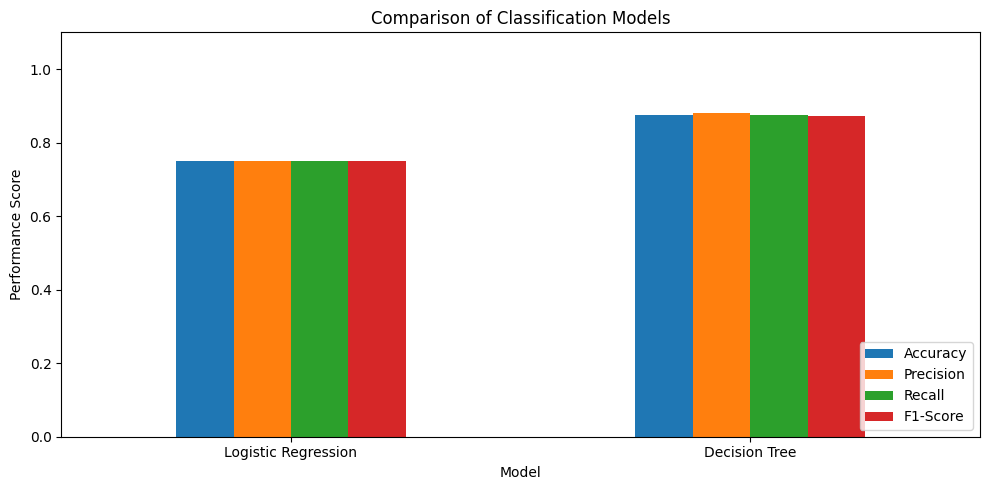

In [36]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

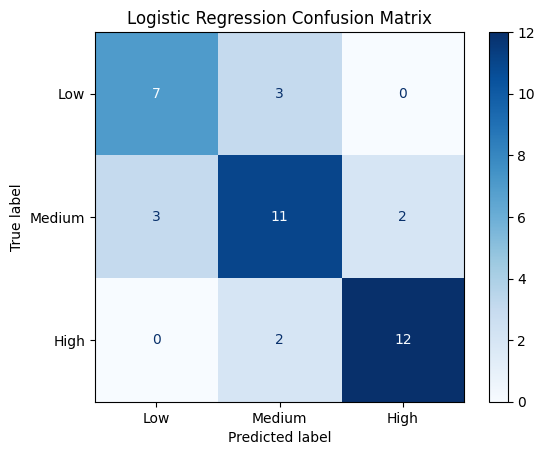

In [37]:
cm_logistic = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

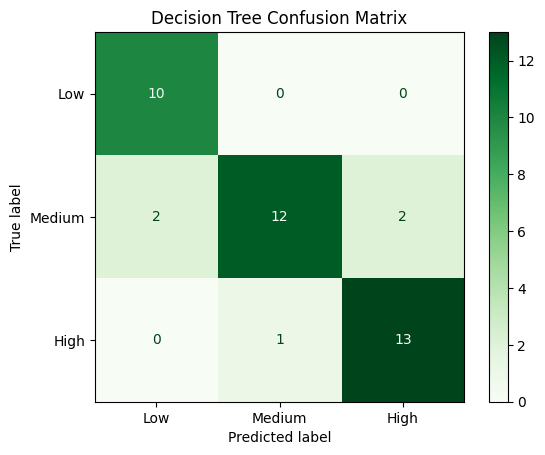

In [38]:
cm_decision = confusion_matrix(
    y_test,
    decision_predictions,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_decision,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [39]:
print("LOGISTIC REGRESSION REPORT")
print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

print("\nDECISION TREE REPORT")
print(
    classification_report(
        y_test,
        decision_predictions,
        zero_division=0
    )
)

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

        High       0.86      0.86      0.86        14
         Low       0.70      0.70      0.70        10
      Medium       0.69      0.69      0.69        16

    accuracy                           0.75        40
   macro avg       0.75      0.75      0.75        40
weighted avg       0.75      0.75      0.75        40


DECISION TREE REPORT
              precision    recall  f1-score   support

        High       0.87      0.93      0.90        14
         Low       0.83      1.00      0.91        10
      Medium       0.92      0.75      0.83        16

    accuracy                           0.88        40
   macro avg       0.87      0.89      0.88        40
weighted avg       0.88      0.88      0.87        40



,Feature,Importance
3,num__Avg_Order_Value,0.454379
2,num__Purchase_Frequency,0.429269
4,num__Membership_Years,0.035859
10,cat__Income_Level_Low Income,0.033141
0,num__Age,0.018193
5,num__Website_Visits,0.015552
1,num__Annual_Income,0.013605
6,cat__Age_Group_Adult,0.000000
7,cat__Age_Group_Senior,0.000000
8,cat__Age_Group_Young,0.000000


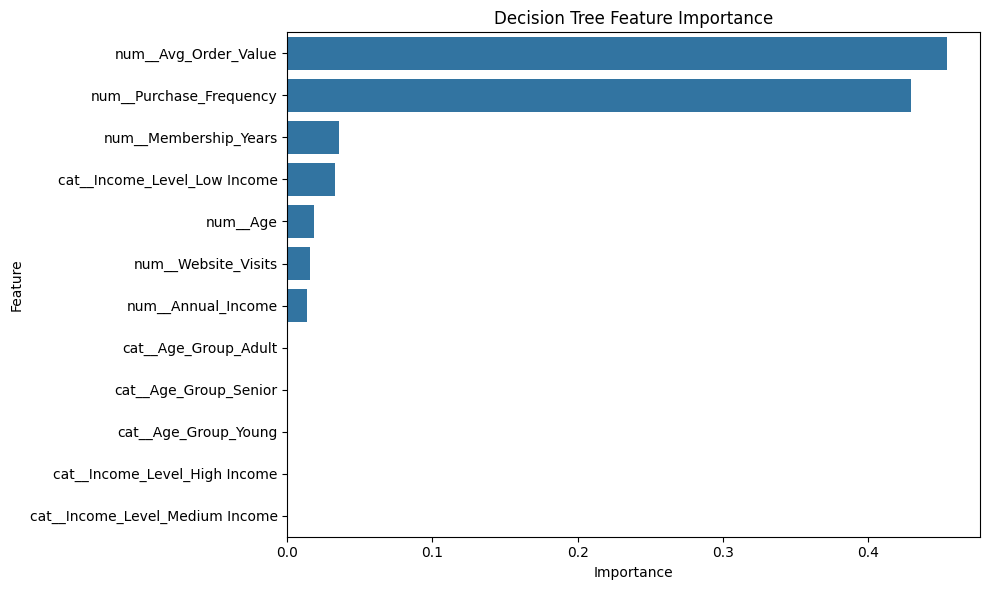

In [40]:
preprocessor = decision_model.named_steps["preprocessing"]

classifier = decision_model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()

In [41]:
def predict_customer_spending(
    age,
    annual_income,
    purchase_frequency,
    avg_order_value,
    membership_years,
    website_visits
):

    age_group = pd.cut(
        [age],
        bins=[17, 25, 40, 60],
        labels=["Young", "Adult", "Senior"]
    )[0]

    income_level = pd.cut(
        [annual_income],
        bins=[0, 500000, 1000000, float("inf")],
        labels=["Low Income", "Medium Income", "High Income"]
    )[0]

    customer = pd.DataFrame({
        "Age": [age],
        "Annual_Income": [annual_income],
        "Purchase_Frequency": [purchase_frequency],
        "Avg_Order_Value": [avg_order_value],
        "Membership_Years": [membership_years],
        "Website_Visits": [website_visits],
        "Age_Group": [age_group],
        "Income_Level": [income_level]
    })

    logistic_result = logistic_model.predict(customer)[0]
    decision_result = decision_model.predict(customer)[0]

    print("Logistic Regression Prediction:", logistic_result)
    print("Decision Tree Prediction:", decision_result)

    return logistic_result, decision_result


predict_customer_spending(
    age=28,
    annual_income=600000,
    purchase_frequency=8,
    avg_order_value=2500,
    membership_years=3,
    website_visits=15
)

Logistic Regression Prediction: Medium
Decision Tree Prediction: Medium


('Medium', 'Medium')

In [42]:
print("CUSTOMER SPENDING BUSINESS INSIGHTS")
print("-----------------------------------")

print("\n1. Total Customers:", len(df))

print("\n2. Spending Category Distribution:")
print(df["Spending_Category"].value_counts())

print("\n3. Average Annual Income:")
print(round(df["Annual_Income"].mean(), 2))

print("\n4. Average Purchase Frequency:")
print(round(df["Purchase_Frequency"].mean(), 2))

print("\n5. Average Order Value:")
print(round(df["Avg_Order_Value"].mean(), 2))

print("\n6. Most Important Decision Tree Features:")
print(importance.head(3))

CUSTOMER SPENDING BUSINESS INSIGHTS
-----------------------------------

1. Total Customers: 200

2. Spending Category Distribution:
Spending_Category
Medium    78
High      70
Low       52
Name: count, dtype: int64

3. Average Annual Income:
800132.43

4. Average Purchase Frequency:
7.73

5. Average Order Value:
2860.5

6. Most Important Decision Tree Features:
                   Feature  Importance
3     num__Avg_Order_Value    0.454379
2  num__Purchase_Frequency    0.429269
4    num__Membership_Years    0.035859


In [43]:
results.to_csv(
    "model_comparison_results.csv",
    index=False
)

importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [44]:
print("AI-BASED CUSTOMER SPENDING PREDICTION")
print("-------------------------------------")

print("Day 1: Dataset Understanding - Completed")
print("Day 2: Data Cleaning and EDA - Completed")
print("Day 3: Feature Engineering and Model Training - Completed")
print("Day 4: Model Evaluation and Analysis - Completed")

print("\nModels evaluated:")
print("1. Logistic Regression")
print("2. Decision Tree")

print("\nFinal model comparison:")
display(results.round(3))

print("\nProject evaluation completed!")

AI-BASED CUSTOMER SPENDING PREDICTION
-------------------------------------
Day 1: Dataset Understanding - Completed
Day 2: Data Cleaning and EDA - Completed
Day 3: Feature Engineering and Model Training - Completed
Day 4: Model Evaluation and Analysis - Completed

Models evaluated:
1. Logistic Regression
2. Decision Tree

Final model comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.750,0.750,0.750,0.750
1,Decision Tree,0.875,0.881,0.875,0.872



Project evaluation completed!
